In [76]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path

csv_path = Path(r"C:\Users\glint\Downloads\archive\amz_uk_price_prediction_dataset.csv")
print(csv_path)

C:\Users\glint\Downloads\archive\amz_uk_price_prediction_dataset.csv


In [77]:
df = pd.read_csv(csv_path)

In [8]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [9]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [11]:
df.shape

(2443651, 9)

In [5]:
# Frequency table
category_counts = df['category'].value_counts()

print(category_counts)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64


**Part 1:** Understanding Product Categories
Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

Frequency Tables:

Generate a frequency table for the product category.
Which are the top 5 most listed product categories?

Visualizations:

Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [6]:
top5_categories = category_counts.head(5)
print(top5_categories)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


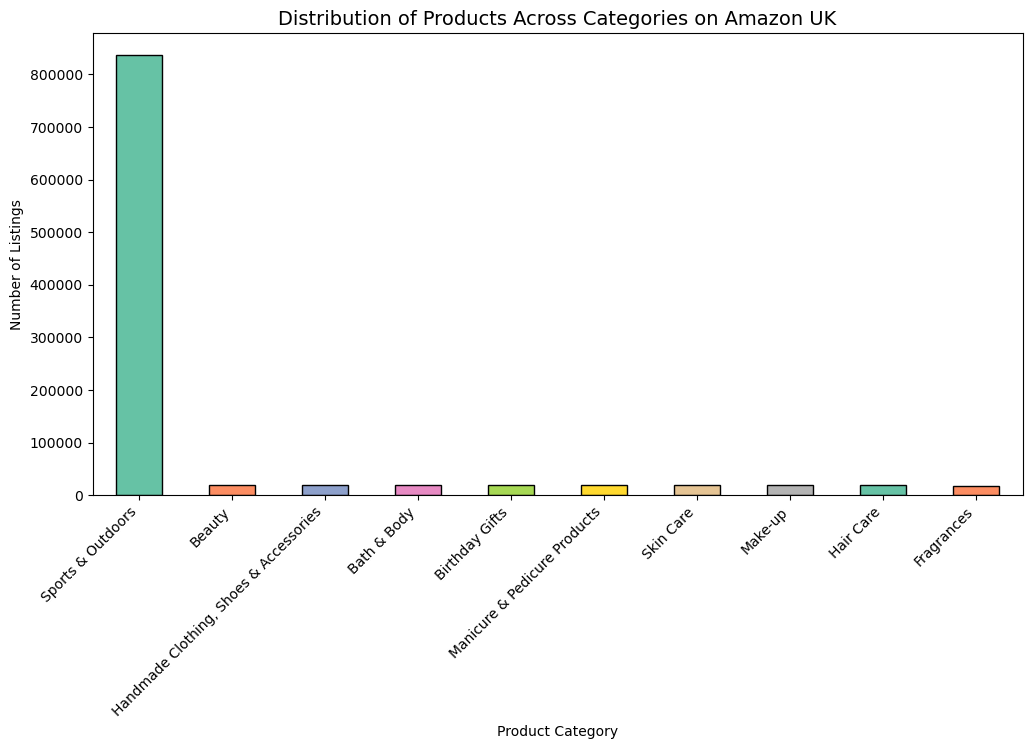

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

# Frequency table for categories
category_counts = df['category'].value_counts().head(10)

# Bar chart for all categories
plt.figure(figsize=(12,6))
category_counts.plot.bar(
    color=sns.color_palette("Set2"),
    edgecolor="black"
)
plt.title("Distribution of Products Across Categories on Amazon UK", fontsize=14)
plt.xlabel("Product Category")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45, ha='right')
plt.show()

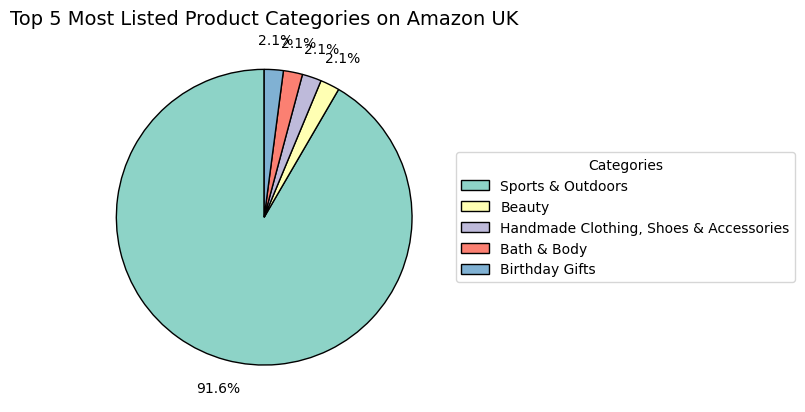

In [82]:
colors = sns.color_palette("Set3", n_colors=5)

# Plot pie chart
top5_categories.plot.pie(
    autopct='%1.1f%%',        # show only percentages
    startangle=90,
    colors=colors,
    labels=None,              # no labels on slices
    wedgeprops={'edgecolor': 'k'},
    fontsize=10,
    pctdistance=1.2           # move percentages outside
)

# Add a legend outside
plt.legend(
    labels=top5_categories.index,
    title="Categories",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Top 5 Most Listed Product Categories on Amazon UK", fontsize=14)
plt.ylabel("")  # remove y-label
plt.show()

**Part 2:** Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

Measures of Centrality:

Calculate the mean, median, and mode for the price of products.
What's the average price point of products listed? How does this compare with the most common price point (mode)?

Measures of Dispersion:

Determine the variance, standard deviation, range, and interquartile range for product price.
How varied are the product prices? Are there any indicators of a significant spread in prices?

Visualizations:

Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

In [83]:
df["price"].describe().round(2)

count    2443651.00
mean          89.24
std          345.61
min            0.00
25%            9.99
50%           19.09
75%           45.99
max       100000.00
Name: price, dtype: float64

In [84]:
#Mean → Average price of all products
#Median → Middle price when all products are sorted
#Mode → Most frequently listed price

mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

print(f"Mean price: {mean_price: .2f}")
print(f"Median price: {median_price: .2f}")
print (f"Mode price: {mode_price: .2f}")

# The avarage (mean) price is approximately 10 times higher than the most frequent price (mode).

Mean price:  89.24
Median price:  19.09
Mode price:  9.99


In [85]:
variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])

print(f"Variance price: {variance_price: .2f}")
print(f"Std dev price: {std_dev_price: .2f}")
print(f"Min price: {min_price: .2f}")
print(f"Max price: {max_price: .2f}")
print(f"Range price: {range_price: .2f}")
print(f"Quantiles price: {quantiles_price}")

Variance price:  119445.49
Std dev price:  345.61
Min price:  0.00
Max price:  100000.00
Range price:  100000.00
Quantiles price: 0.25     9.99
0.50    19.09
0.75    45.99
Name: price, dtype: float64


**Insights:**
- **Centrality**:
  - The most frequent (mode) price is £9.99. This value appears more frequently than any other price in the dataset.
  - The average (mean) price of the products in the dataset is approximately `£89.24`.
  - The median price (middle value when sorted) stands at `£19.09`. Notably, the median is lower than the mean, suggesting a skew in the distribution of sale prices towards higher values.
  
- **Dispersion**:
- The standard deviation, a measure of the amount of variation or dispersion in the prices, is approximately `£345.61`. This indicates that prices can vary significantly from the average.

- The minimum and maximum sale prices are `£0.00` and `£100000`, respectively, highlighting a wide range of price values in the dataset.

- The interquartile range (IQR), given by the values at 25% (Q1) and 75% (Q3), is between `£9.99` and `£45.99`. This means that 100% of the products in the dataset were sold within this price range.

In [86]:
df['price'].quantile(0.1) # We can get any quantile value, not just quartiles

np.float64(5.99)

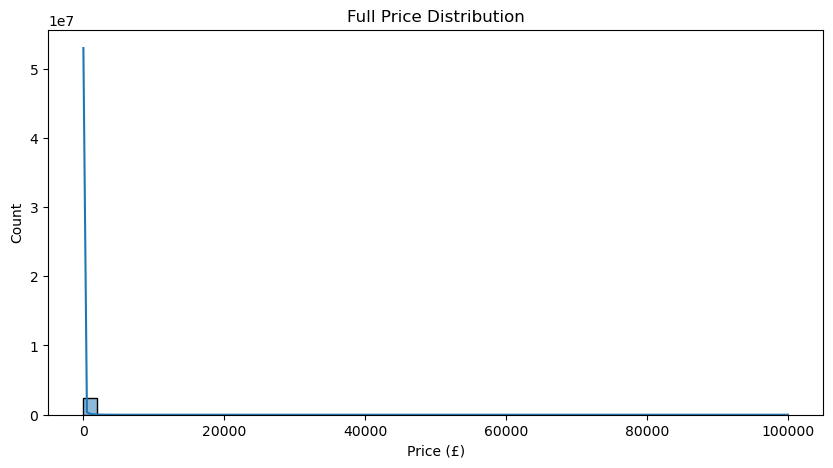

In [90]:
# Full distribution
plt.figure(figsize=(10,5))
sns.histplot(df['price'], bins=50, kde=True)
plt.title("Full Price Distribution")
plt.xlabel("Price (£)")
plt.ylabel("Count")
plt.show()

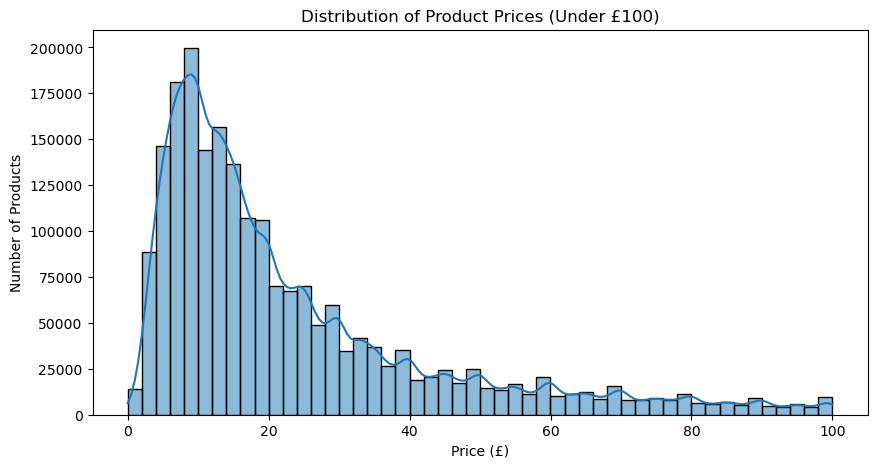

In [ ]:
# Under £100 price
plt.figure(figsize=(10,5))  

sns.histplot(df[df['price'] < 100]['price'], bins=50, kde=True)

plt.title("Distribution of Product Prices (Under £100)")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")

plt.show()

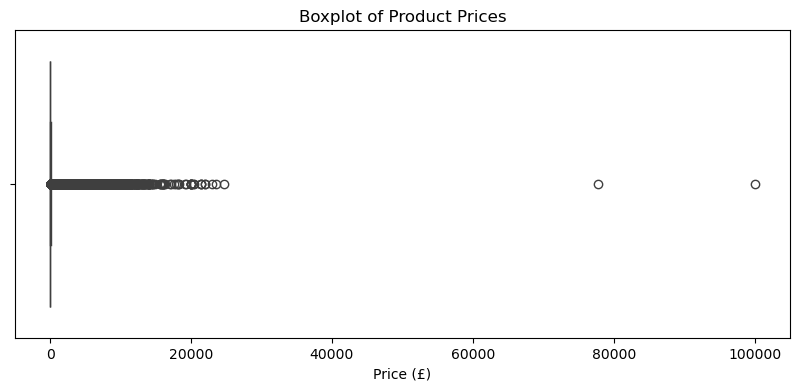

In [74]:
plt.figure(figsize=(10,4))

sns.boxplot(x=df['price'])

plt.title("Boxplot of Product Prices")
plt.xlabel("Price (£)")

plt.show()

**Insights:**
Most products cluster in a low price range (e.g., £5–£40)

Distribution is heavily right-skewed

Many outliers on the high end

A few products are much more expensive than the rest

**Part 3:** Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

Measures of Centrality:

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?

Measures of Dispersion:

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?

Shape of the Distribution:

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?

Visualizations:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [ ]:
# Measure of Centrality:
rating_mean = df["stars"].mean()
rating_median = df["stars"].median()
rating_mode = df["stars"].mode()[0]

print(f"Rating mean: {rating_mean: .2f}")
print(f"Rating median: {rating_median: .2f}")
print(f"Rating mode: {rating_mode: .2f}")

#Mean is higher than median what indicates right skewness

Rating mean:  2.15
Rating median:  0.00
Rating mode:  0.00


In [ ]:
# Measure of Dispersion:
# Variance measures how far the values in a dataset are spread out from the mean (average).
# Standard deviation is the square root of variance.
rating_varience = df["stars"].var()
rating_st_dev = df["stars"].std()
rating_quantile = df["stars"].quantile([0.25, 0.5, 0.75])
rating_max = df["stars"].max()
rating_min = df["stars"].min()

print(f"Rating variance: {rating_varience: .2f}")
print(f"Rating st deviation: {rating_st_dev: .2f}")
print(f"Rating quartile: {rating_quantile}")
print(f"Rating max: {rating_max}")
print(f"Rating min: {rating_min}")

# Ratings are concentrated between 4 and 5 stars
# Low standard deviation >> little variation
# Most products are well rated >> strong positive bias
# Few low-rating outliers

Rating variance:  4.82
Rating st deviation:  2.19
Rating quartile: 0.25    0.0
0.50    0.0
0.75    4.4
Name: stars, dtype: float64
Rating max: 5.0
Rating min: 0.0


In [ ]:
skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()

print(f"Skewness rating: {skewness_rating: .2f}")
print(f"Kurtosis rating: {kurtosis_rating: .2f}")

# Ratings are evenly distributed around the mean, with no strong left or right skew.
# Fewer extreme outliers.
# Data is more spread out across values.

Skewness rating:  0.08
Kurtosis rating: -1.93


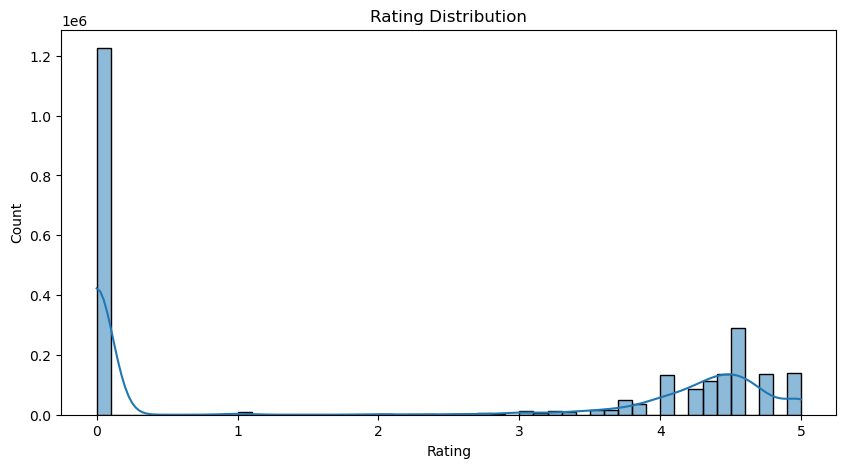

In [ ]:
# Visualisation:
plt.figure(figsize=(10,5))

sns.histplot(df['stars'], bins=50, kde=True)

plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Count")

plt.show() 

# The majority of users do not leave the rating note.
# Most of users left the positive note between 4 and 5 start.
# The lower ratings are mostly insignificant, with small spikes at 1 and 3 stars.